In [2]:
# ==========================
# Cell 1 – Imports, Global Setup & Data Loading
# ==========================

# Core Python & utilities
import os
import random
from pathlib import Path
from collections import Counter
from math import pi

# Numerical & data handling
import numpy as np
import pandas as pd

# Plotting & visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image handling & feature extraction
from PIL import Image
from skimage.feature import (
    hog,
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

# Machine learning: model building & evaluation
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    log_loss
)

# Classifiers specified in the proposal
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

# Misc: styling & warnings
import warnings
warnings.filterwarnings("ignore")

# --------------------------
# Global configuration
# --------------------------

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# NOTE: Folder-based paths not needed for HF version, kept only for reference
DATA_ROOT = Path("/path/to/BrainTumorDatasets")
TRAIN_DIR = DATA_ROOT / "Training"
TEST_DIR = DATA_ROOT / "Testing"

# Plot style
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (6, 4)

# --------------------------
# Load HuggingFace dataset
# --------------------------
from datasets import load_dataset

# Load the 4-class brain tumor dataset
multi_ds = load_dataset("Cayanaaa/BrainTumorDatasets", name="multiclass")

train_hf = multi_ds["train"]
test_hf = multi_ds["test"]

print("=== HuggingFace Dataset Info ===")
print(train_hf)
print(test_hf)

# Basic dataset summary for data analysis
print("\nNumber of training examples:", len(train_hf))
print("Number of test examples    :", len(test_hf))

# Show label names (will be used later)
label_names = train_hf.features["label"].names
print("\nLabel names:", label_names)

# Peek at one example to understand structure
example0 = train_hf[0]
print("\nExample 0 keys:", example0.keys())
print("Type of image :", type(example0["image"]))
print("Label (id)    :", example0["label"])


=== HuggingFace Dataset Info ===
Dataset({
    features: ['image', 'label'],
    num_rows: 5712
})
Dataset({
    features: ['image', 'label'],
    num_rows: 1311
})

Number of training examples: 5712
Number of test examples    : 1311

Label names: ['glioma', 'meningioma', 'notumor', 'pituitary']

Example 0 keys: dict_keys(['image', 'label'])
Type of image : <class 'PIL.JpegImagePlugin.JpegImageFile'>
Label (id)    : 0


Label mapping (id -> name): {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}
Training examples: 5712
label
notumor       1595
pituitary     1457
meningioma    1339
glioma        1321
Name: count, dtype: int64 

Test examples: 1311
label
notumor       405
meningioma    306
glioma        300
pituitary     300
Name: count, dtype: int64


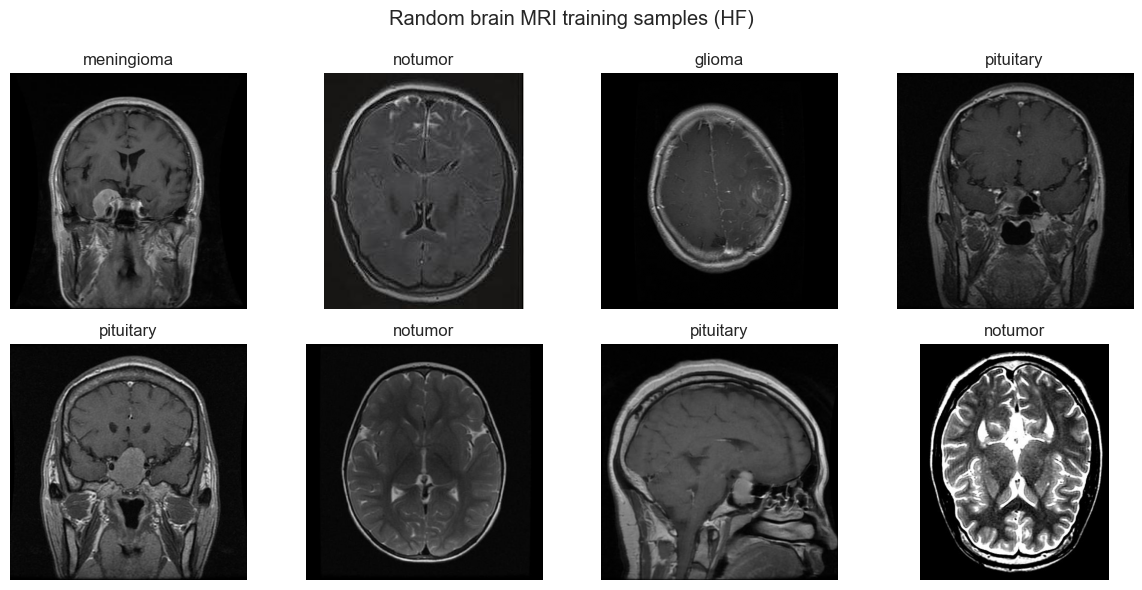

In [3]:
# Cell 2 – Wrap HF dataset in DataFrames & visualize samples
# ==========================

# 1) Label ID -> name mapping from HF metadata
label_id2name = {
    i: name for i, name in enumerate(train_hf.features["label"].names)
}
print("Label mapping (id -> name):", label_id2name)

# 2) Build Pandas DataFrames (index + label info) for convenience
train_labels_str = [label_id2name[i] for i in train_hf["label"]]
test_labels_str  = [label_id2name[i] for i in test_hf["label"]]

train_df = pd.DataFrame({
    "index": np.arange(len(train_hf)),
    "label_id": train_hf["label"],
    "label": train_labels_str,
    "subset": "train",
})

test_df = pd.DataFrame({
    "index": np.arange(len(test_hf)),
    "label_id": test_hf["label"],
    "label": test_labels_str,
    "subset": "test",
})

print("Training examples:", len(train_df))
print(train_df["label"].value_counts(), "\n")

print("Test examples:", len(test_df))
print(test_df["label"].value_counts())


# 3) Quick visualization of random samples from HF dataset
def show_random_samples_hf(dataset, n=8, title="Random samples from HF dataset"):
    """
    Show n random images from a HuggingFace Dataset with 'image' and 'label' fields.
    """
    n = min(n, len(dataset))
    indices = np.random.choice(len(dataset), size=n, replace=False)

    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, indices):
        example = dataset[int(idx)]
        img = example["image"]
        # HF 'image' can already be a PIL.Image; if not, convert from array
        if not isinstance(img, Image.Image):
            img = Image.fromarray(np.array(img))

        label_name = label_id2name[example["label"]]
        ax.imshow(img, cmap="gray")
        ax.set_title(label_name)
        ax.axis("off")

    # Hide any unused axes
    for ax in axes[len(indices):]:
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Show a few training examples
show_random_samples_hf(train_hf, n=8, title="Random brain MRI training samples (HF)")


In [4]:
# Cell 3 – Image preprocessing & feature extraction (HOG + LBP + GLCM)
# ==========================

# Global settings for feature extraction
IMG_SIZE = (128, 128)   # resize all images to this size
LBP_P = 8               # number of circularly symmetric neighbour points
LBP_R = 1               # radius for LBP
GLCM_LEVELS = 16        # quantization levels for GLCM


def preprocess_image(img, target_size=IMG_SIZE):
    """
    Convert HF image to grayscale, resize, and normalize to [0, 1].
    """
    # HF images are usually PIL.Image already, but we handle arrays too
    if not isinstance(img, Image.Image):
        img = Image.fromarray(np.array(img))

    # Convert to grayscale
    img = img.convert("L")  # 'L' = 8-bit pixels, black and white

    # Resize
    img = img.resize(target_size, Image.BILINEAR)

    # To numpy float32 and scale to [0, 1]
    arr = np.array(img).astype("float32") / 255.0
    return arr


def extract_hog_features(img_arr):
    """
    Compute HOG (Histogram of Oriented Gradients) features on a 2D grayscale image.
    """
    features = hog(
        img_arr,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        transform_sqrt=True,
        feature_vector=True
    )
    return features


def extract_lbp_features(img_arr, P=LBP_P, R=LBP_R):
    """
    Compute LBP codes and return a normalized histogram as texture features.
    """
    lbp = local_binary_pattern(img_arr, P=P, R=R, method="uniform")
    n_bins = P + 2  # 'uniform' LBP has P+2 possible output values

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins),
        density=True  # returns normalized histogram
    )
    return hist


def extract_glcm_features(img_arr, levels=GLCM_LEVELS):
    """
    Compute GLCM (Gray-Level Co-occurrence Matrix) and extract several properties.
    """
    # Quantize image to a small number of gray levels [0, levels-1]
    arr = (img_arr * (levels - 1)).astype("uint8")

    distances = [1, 2]
    angles = [0, pi / 4, pi / 2, 3 * pi / 4]

    glcm = graycomatrix(
        arr,
        distances=distances,
        angles=angles,
        levels=levels,
        symmetric=True,
        normed=True
    )

    props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    feats = []

    for prop in props:
        vals = graycoprops(glcm, prop)  # shape: (len(distances), len(angles))
        feats.append(vals.ravel())

    return np.concatenate(feats, axis=0)


def extract_features_for_example(example):
    """
    Full feature pipeline for a single HF example:
    preprocess -> HOG + LBP + GLCM -> concatenate into one vector.
    """
    img = example["image"]
    img_arr = preprocess_image(img)

    hog_feats = extract_hog_features(img_arr)
    lbp_feats = extract_lbp_features(img_arr)
    glcm_feats = extract_glcm_features(img_arr)

    return np.concatenate([hog_feats, lbp_feats, glcm_feats], axis=0)


def build_feature_matrix(hf_dataset, desc="train"):
    """
    Apply feature extraction to every image in a HF dataset split.

    Returns:
        X : 2D numpy array (n_samples, n_features)
        y : 1D numpy array (n_samples,)
    """
    X_list = []
    y_list = []
    n = len(hf_dataset)

    for i, example in enumerate(hf_dataset):
        feats = extract_features_for_example(example)
        X_list.append(feats)
        y_list.append(example["label"])   # numeric label (0..3)

        if (i + 1) % 500 == 0 or (i + 1) == n:
            print(f"{desc}: processed {i + 1}/{n} images")

    X = np.vstack(X_list).astype("float32")
    y = np.array(y_list, dtype="int64")
    return X, y


# Build feature matrices for train and test splits
X_train, y_train = build_feature_matrix(train_hf, desc="train")
X_test, y_test = build_feature_matrix(test_hf, desc="test")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


train: processed 500/5712 images
train: processed 1000/5712 images
train: processed 1500/5712 images
train: processed 2000/5712 images
train: processed 2500/5712 images
train: processed 3000/5712 images
train: processed 3500/5712 images
train: processed 4000/5712 images
train: processed 4500/5712 images
train: processed 5000/5712 images
train: processed 5500/5712 images
train: processed 5712/5712 images
test: processed 500/1311 images
test: processed 1000/1311 images
test: processed 1311/1311 images
X_train shape: (5712, 8158)
y_train shape: (5712,)
X_test shape: (1311, 8158)
y_test shape: (1311,)


Scaled feature shapes:
X_train_scaled: (5712, 8158)
X_test_scaled: (1311, 8158)
Training model: Logistic Regression
Accuracy: 0.9428

Classification report:
              precision    recall  f1-score   support

      glioma       0.93      0.89      0.91       300
  meningioma       0.89      0.88      0.89       306
     notumor       0.98      1.00      0.99       405
   pituitary       0.95      0.98      0.97       300

    accuracy                           0.94      1311
   macro avg       0.94      0.94      0.94      1311
weighted avg       0.94      0.94      0.94      1311



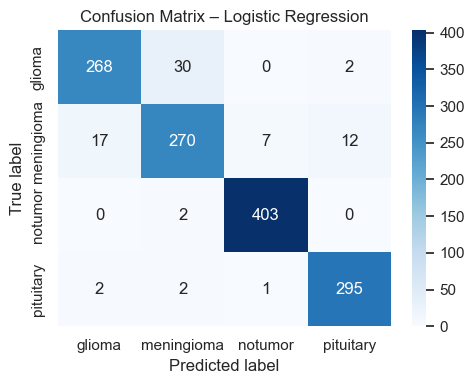

Training model: Decision Tree
Accuracy: 0.8719

Classification report:
              precision    recall  f1-score   support

      glioma       0.88      0.79      0.83       300
  meningioma       0.76      0.83      0.79       306
     notumor       0.95      0.97      0.96       405
   pituitary       0.89      0.87      0.88       300

    accuracy                           0.87      1311
   macro avg       0.87      0.86      0.87      1311
weighted avg       0.87      0.87      0.87      1311



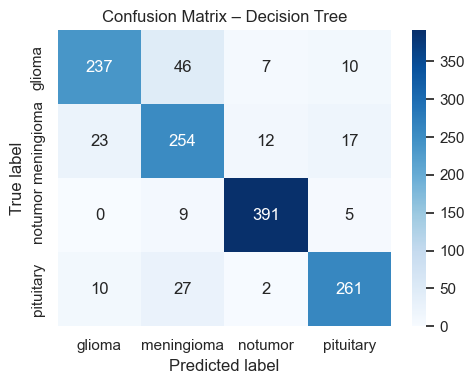

Training model: KNN (k=8)
Accuracy: 0.8993

Classification report:
              precision    recall  f1-score   support

      glioma       0.93      0.93      0.93       300
  meningioma       0.89      0.69      0.77       306
     notumor       0.91      0.97      0.94       405
   pituitary       0.87      0.99      0.93       300

    accuracy                           0.90      1311
   macro avg       0.90      0.89      0.89      1311
weighted avg       0.90      0.90      0.90      1311



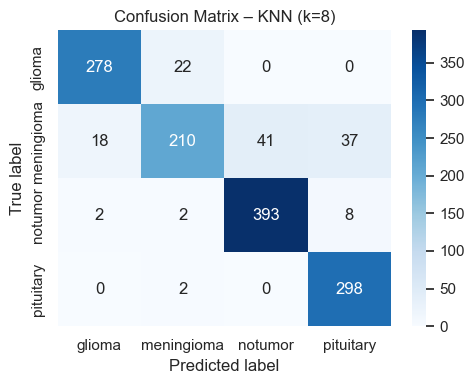

Training model: MLP
Accuracy: 0.9527

Classification report:
              precision    recall  f1-score   support

      glioma       0.94      0.91      0.93       300
  meningioma       0.91      0.89      0.90       306
     notumor       0.98      1.00      0.99       405
   pituitary       0.97      1.00      0.98       300

    accuracy                           0.95      1311
   macro avg       0.95      0.95      0.95      1311
weighted avg       0.95      0.95      0.95      1311



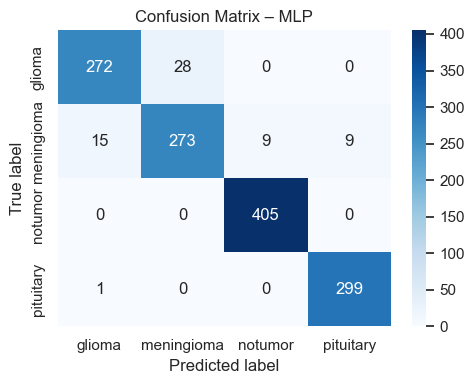

Training model: SVM (RBF)
Accuracy: 0.9680

Classification report:
              precision    recall  f1-score   support

      glioma       0.99      0.91      0.94       300
  meningioma       0.91      0.96      0.93       306
     notumor       0.99      1.00      0.99       405
   pituitary       0.99      1.00      0.99       300

    accuracy                           0.97      1311
   macro avg       0.97      0.97      0.97      1311
weighted avg       0.97      0.97      0.97      1311



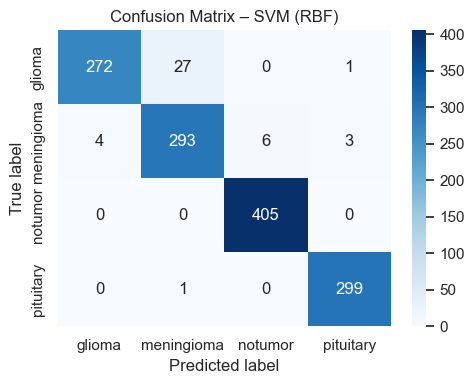

In [5]:
# Cell 4 – Feature scaling, model training & evaluation 
# ==========================

# 1) Scale features (good for LR, KNN, MLP, SVM; harmless for tree)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled feature shapes:")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)


# 2) Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        multi_class="multinomial",
        solver="lbfgs",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=None,          # you can tune later
        min_samples_split=2
    ),
    "KNN (k=8)": KNeighborsClassifier(
        n_neighbors=5,
        weights="uniform",
        metric="minkowski"
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        solver="adam",
        max_iter=300,
        random_state=RANDOM_STATE,
        early_stopping=True
    ),
    "SVM (RBF)": SVC(            # <<--- New SVM model
        kernel="rbf",
        C=10.0,
        gamma="scale",
        probability=True,        # needed for predict_proba (ROC–AUC, log loss)
        random_state=RANDOM_STATE
    ),
}

# Class names for reports & confusion matrices
label_order = sorted(label_id2name.keys())  # [0,1,2,3]
class_names = [label_id2name[i] for i in label_order]


def plot_confusion(y_true, y_pred, title="Confusion matrix"):
    """
    Plot a confusion matrix heatmap.
    """
    cm = confusion_matrix(y_true, y_pred, labels=label_order)
    cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(title)
    plt.tight_layout()
    plt.show()


results = []

# 3) Train & evaluate each model
for name, model in models.items():
    print("=" * 60)
    print(f"Training model: {name}")
    print("=" * 60)

    # Fit on scaled training data
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        output_dict=True
    )

    macro_prec = report["macro avg"]["precision"]
    macro_rec = report["macro avg"]["recall"]
    macro_f1 = report["macro avg"]["f1-score"]

    print(f"Accuracy: {acc:.4f}")
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=class_names))

    # Plot confusion matrix
    plot_confusion(y_test, y_pred, title=f"Confusion Matrix – {name}")

    # Save results for comparison table
    results.append({
        "model": name,
        "accuracy": acc,
        "macro_precision": macro_prec,
        "macro_recall": macro_rec,
        "macro_f1": macro_f1,
    })

# 4) Summary table comparing all models
results_df = pd.DataFrame(results).set_index("model").sort_values("accuracy", ascending=False)


In [6]:
# Cell 5 – Model comparison, ROC–AUC, log loss, best model selection & saving
# ==========================

# Start with the accuracy + macro metrics we already collected in Cell 4
print("\n\n====================== MODEL COMPARISON (BASE METRICS) ======================")

# Pretty display if running in Jupyter
try:
    from IPython.display import display
    display(results_df)
except ImportError:
    # Fallback for plain .py script
    print(results_df)


# --------------------------------------------------
# Add ROC–AUC (macro, one-vs-rest) and log loss
# --------------------------------------------------
print("\nComputing ROC–AUC (macro, OVR) and log loss for each model...")

for name, model in models.items():
    # Some models might not have predict_proba, but ours do (incl. SVM with probability=True).
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_scaled)

        # Multi-class ROC–AUC, one-vs-rest, macro-averaged
        try:
            roc_auc = roc_auc_score(
                y_test,
                y_proba,
                multi_class="ovr",
                average="macro"
            )
        except Exception as e:
            print(f"Warning: could not compute ROC–AUC for {name}: {e}")
            roc_auc = np.nan

        # Log loss (cross-entropy)
        try:
            ll = log_loss(y_test, y_proba)
        except Exception as e:
            print(f"Warning: could not compute log loss for {name}: {e}")
            ll = np.nan
    else:
        roc_auc = np.nan
        ll = np.nan

    # Add these metrics as new columns in results_df
    results_df.loc[name, "roc_auc_macro_ovr"] = roc_auc
    results_df.loc[name, "log_loss"] = ll

# Reorder columns for nicer view
cols_order = [
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "roc_auc_macro_ovr",
    "log_loss",
]
results_df = results_df[cols_order].sort_values("accuracy", ascending=False)

print("\n\n====================== MODEL COMPARISON (WITH ROC–AUC & LOG LOSS) ======================")
try:
    display(results_df)
except NameError:
    print(results_df)


# --------------------------------------------------
# Pick best model (by accuracy) and save it + scaler
# --------------------------------------------------
best_model_name = results_df["accuracy"].idxmax()
best_acc = results_df.loc[best_model_name, "accuracy"]
best_roc = results_df.loc[best_model_name, "roc_auc_macro_ovr"]
best_ll = results_df.loc[best_model_name, "log_loss"]

print(f"\nBest model (by test accuracy): {best_model_name}")
print(f"  Accuracy:        {best_acc:.4f}")
print(f"  ROC–AUC (macro): {best_roc:.4f}")
print(f"  Log loss:        {best_ll:.4f}")

# Get the actual trained model object from the 'models' dict (defined in Cell 4)
best_model = models[best_model_name]

# Save best model + scaler
import joblib
safe_name = best_model_name.replace(" ", "_")
model_filename = f"best_brain_tumor_model_{safe_name}.joblib"
scaler_filename = "feature_scaler.joblib"

joblib.dump(best_model, model_filename)
joblib.dump(scaler, scaler_filename)

print("\nSaved to disk:")
print(f"  Model : {model_filename}")
print(f"  Scaler: {scaler_filename}")




====================== MODEL COMPARISON (BASE METRICS) ======================


,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
SVM (RBF),0.967963,0.967620,0.965212,0.965852
MLP,0.952708,0.950115,0.948873,0.949310
Logistic Regression,0.942792,0.939296,0.938520,0.938727
KNN (k=8),0.899314,0.899263,0.894161,0.892102
Decision Tree,0.871854,0.868386,0.863874,0.865072



Computing ROC–AUC (macro, OVR) and log loss for each model...


====================== MODEL COMPARISON (WITH ROC–AUC & LOG LOSS) ======================


,accuracy,macro_precision,macro_recall,macro_f1,roc_auc_macro_ovr,log_loss
model,,,,,,
SVM (RBF),0.967963,0.967620,0.965212,0.965852,0.997932,0.081112
MLP,0.952708,0.950115,0.948873,0.949310,0.993406,0.195258
Logistic Regression,0.942792,0.939296,0.938520,0.938727,0.991551,0.334548
KNN (k=8),0.899314,0.899263,0.894161,0.892102,0.989560,0.342779
Decision Tree,0.871854,0.868386,0.863874,0.865072,0.910804,4.618866



Best model (by test accuracy): SVM (RBF)
  Accuracy:        0.9680
  ROC–AUC (macro): 0.9979
  Log loss:        0.0811

Saved to disk:
  Model : best_brain_tumor_model_SVM_(RBF).joblib
  Scaler: feature_scaler.joblib


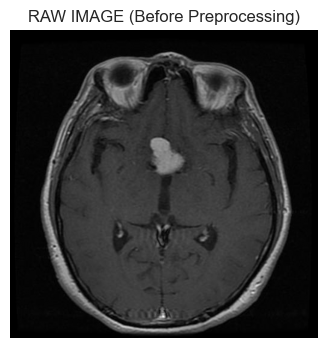

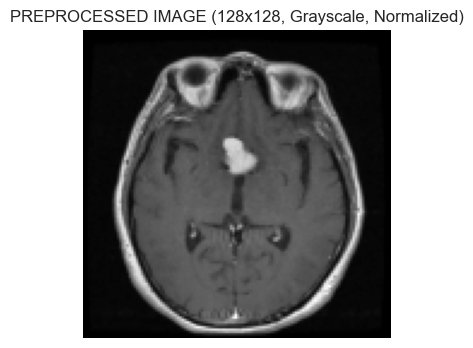

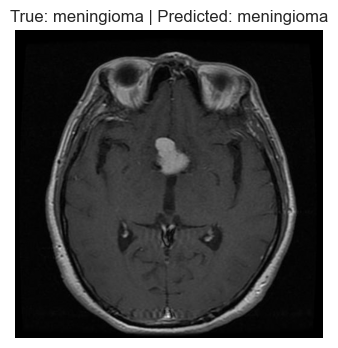

Index in test set: 507
True label     : meningioma (id=1)
Predicted label: meningioma (id=1)

Class probabilities:
  glioma     : 0.0035
  meningioma : 0.7414
  notumor    : 0.0254
  pituitary  : 0.2296


In [10]:
# ==========================
# Cell 6 – Single-image prediction demo (fixed version)
# ==========================

def predict_single_test_example(idx=None, show_probs=True):
    """
    Pick one example from the test split, show the image, and run it
    through the full pipeline using the best model (selected in Cell 5).
    """

    # Ensure best_model exists
    try:
        best_model
    except NameError:
        print("ERROR: best_model is not defined. Run all previous cells first.")
        return

    # Choose a random index if none is provided
    if idx is None:
        idx = np.random.randint(0, len(test_hf))

    example = test_hf[int(idx)]
    img = example["image"]
    true_label_id = example["label"]
    true_label_name = label_id2name[true_label_id]

    # ------------------------------
    # Show raw input image
    # ------------------------------
    if not isinstance(img, Image.Image):
        raw_img = Image.fromarray(np.array(img))
    else:
        raw_img = img

    plt.figure(figsize=(4,4))
    plt.imshow(raw_img, cmap="gray")
    plt.title("RAW IMAGE (Before Preprocessing)")
    plt.axis("off")
    plt.show()

    # ------------------------------
    # Preprocess & extract features
    # ------------------------------
    img_arr = preprocess_image(img)

    plt.figure(figsize=(4,4))
    plt.imshow(img_arr, cmap="gray")
    plt.title("PREPROCESSED IMAGE (128x128, Grayscale, Normalized)")
    plt.axis("off")
    plt.show()

    hog_feats = extract_hog_features(img_arr)
    lbp_feats = extract_lbp_features(img_arr)
    glcm_feats = extract_glcm_features(img_arr)
    full_feats = np.concatenate([hog_feats, lbp_feats, glcm_feats], axis=0)

    # Scale features
    X_feat_scaled = scaler.transform(full_feats.reshape(1, -1))

    # Predict class
    pred_id = best_model.predict(X_feat_scaled)[0]
    pred_name = label_id2name[int(pred_id)]

    # Final result figure
    plt.figure(figsize=(4,4))
    plt.imshow(raw_img, cmap="gray")
    plt.title(f"True: {true_label_name} | Predicted: {pred_name}")
    plt.axis("off")
    plt.show()

    print(f"Index in test set: {idx}")
    print(f"True label     : {true_label_name} (id={true_label_id})")
    print(f"Predicted label: {pred_name} (id={pred_id})")

    # Probabilities
    if show_probs and hasattr(best_model, "predict_proba"):
        print("\nClass probabilities:")
        probs = best_model.predict_proba(X_feat_scaled)[0]
        for class_id, p in enumerate(probs):
            print(f"  {label_id2name[class_id]:<10} : {p:.4f}")


# Run a demo prediction
predict_single_test_example()
